In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
%matplotlib inline

In [2]:
df = pd.read_csv("../data/us_monthly_retail_sales_wrangled.csv")
df.head()

,Unnamed: 0,month,year,naics_Code,kind_of_business,industry,sales
0,0,1,2022,441,Motor vehicle and parts dealers,Automotive,113548.0
1,1,1,2022,"44,114,412",Automobile and other motor vehicle dealers,Automotive,104500.0
2,2,1,2022,4411,Automobile dealers,Automotive,96689.0
3,3,1,2022,44111,New car dealers,Automotive,84442.0
4,4,1,2022,44112,Used car dealers,Automotive,12247.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9048 entries, 0 to 9047
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        9048 non-null   int64  
 1   month             9048 non-null   int64  
 2   year              9048 non-null   int64  
 3   naics_Code        9048 non-null   str    
 4   kind_of_business  9048 non-null   str    
 5   industry          9048 non-null   str    
 6   sales             8787 non-null   float64
dtypes: float64(1), int64(3), str(3)
memory usage: 494.9 KB


In [4]:
# checking the value counts for each column
for column in df.columns:
    print(f"--- Here are the value count for {column} ---")
    print(df[column].value_counts())
    print('\n' + '=' * 50 + '\n')

--- Here are the value count for Unnamed: 0 ---
Unnamed: 0
0       1
1       1
2       1
3       1
4       1
       ..
9043    1
9044    1
9045    1
9046    1
9047    1
Name: count, Length: 9048, dtype: int64


--- Here are the value count for month ---
month
1     754
2     754
3     754
4     754
5     754
6     754
7     754
8     754
9     754
10    754
11    754
12    754
Name: count, dtype: int64


--- Here are the value count for year ---
year
2022    696
2021    696
2020    696
2019    696
2018    696
2017    696
2016    696
2015    696
2014    696
2013    696
2012    696
2011    696
2010    696
Name: count, dtype: int64


--- Here are the value count for naics_Code ---
naics_Code
441                       156
44,114,412                156
4411                      156
44111                     156
44112                     156
4413                      156
442,443                   156
442                       156
4421                      156
4422                      156
44

In [5]:
# Here we check the summary statistics
df.describe(include = 'all').T.head(10)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,9048.0,NaN,NaN,NaN,4523.5,2612.076951,0.0,2261.75,4523.5,6785.25,9047.0
month,9048.0,NaN,NaN,NaN,6.5,3.452243,1.0,3.75,6.5,9.25,12.0
year,9048.0,NaN,NaN,NaN,2016.0,3.741864,2010.0,2013.0,2016.0,2019.0,2022.0
naics_Code,9048,58,441,156,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kind_of_business,9048,58,Motor vehicle and parts dealers,156,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,9048,12,Home Goods & Electronics,1560,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sales,8787.0,NaN,NaN,NaN,21850.771139,26095.151533,11.0,2656.5,8661.0,35223.0,141659.0


In [6]:
# Here we check for any duplicates and memory used from the data
print('Duplicated rows:', df.duplicated().sum())

# Convert bytes to MB and format to 2 decimal places
memory_mb = df.memory_usage(deep = True).sum() / (1024 **2)
print(f'Here is the memory used from this data (MB) : {memory_mb:.2f})')

Duplicated rows: 0
Here is the memory used from this data (MB) : 2.20)


In [7]:
# Here we check for unique values in each column
for column in df.columns:
    print(f"--- Here are the unique value count for {column} ---")
    print(df[column].unique())
    print('\n' + '=' * 50 + '\n')

--- Here are the unique value count for Unnamed: 0 ---
[   0    1    2 ... 9045 9046 9047]


--- Here are the unique value count for month ---
[ 1  2  3  4  5  6  7  8  9 10 11 12]


--- Here are the unique value count for year ---
[2022 2021 2020 2019 2018 2017 2016 2015 2014 2013 2012 2011 2010]


--- Here are the unique value count for naics_Code ---
<StringArray>
[                   '441',             '44,114,412',                   '4411',
                  '44111',                  '44112',                   '4413',
                '442,443',                    '442',                   '4421',
                   '4422',                  '44221',                 '442299',
                    '443',                 '443141',                 '443142',
                    '444',                   '4441',                  '44412',
                  '44413',                    '445',                   '4451',
                  '44511',                   '4453',                    '446'

#### Checking for missing values

In [8]:
# Here we check for any missing value
missing = df.isnull().sum()
missing_df = pd.DataFrame({'Missing values': missing})
missing_df = missing_df[missing_df['Missing values'] > 0].sort_values('Missing values', ascending = False)

if len(missing_df):
    print(missing_df)
else:
    print("There's no explicit NaN values")

       Missing values
sales             261


### **Handling Missing values in the 'sales' column**

In [9]:
# here we impute these missing values with the median
# imputing with median is robust against potential outliers in the sales data

sales_impute = df['sales'].median()
df['sales'] = df['sales'].fillna(sales_impute)

print(f"Missing values in 'sales' after imputation: {df['sales'].isnull().sum()}")

Missing values in 'sales' after imputation: 0


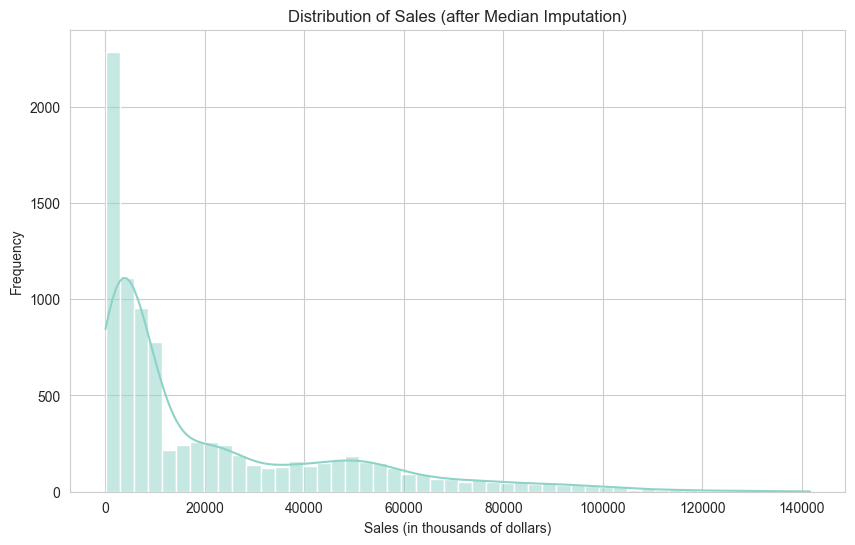

In [10]:
# Visualize the distribution of sales
plt.figure(figsize=(10, 6))
sns.histplot(df['sales'], kde=True, bins=50)
plt.title('Distribution of Sales (after Median Imputation)')
plt.xlabel('Sales (in thousands of dollars)')
plt.ylabel('Frequency')
plt.show()

### **Univariate Analysis from the Numerical Features**

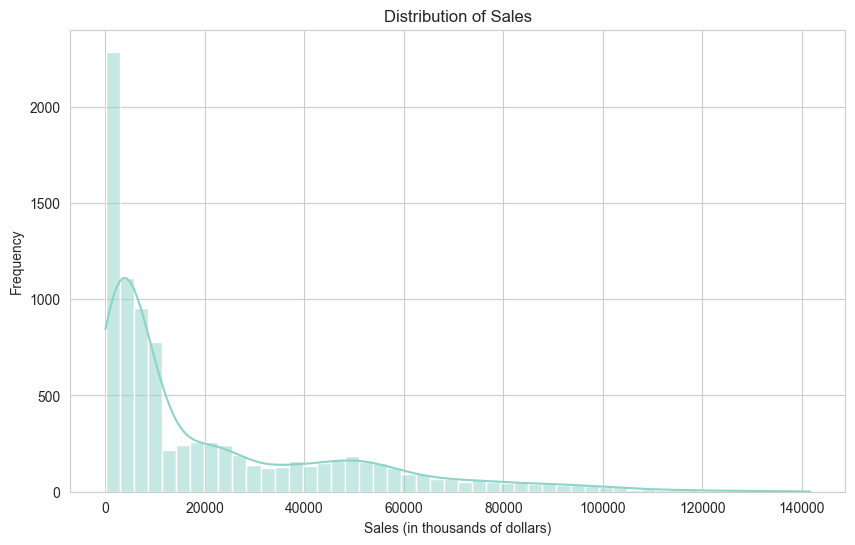

In [11]:
plt.figure(figsize = (10, 6))
sns.histplot(df['sales'], kde = True, bins = 50)
plt.title('Distribution of Sales')
plt.xlabel('Sales (in thousands of dollars)')
plt.ylabel('Frequency')
plt.show()

### **Bivariate Analysis; Sales by Industry**

In [12]:
# Here we identify the Top performing industry with highest median sales
# we consider the median since its robust against outliers and also resistance to skewed distribution
top_performing_industry = df.groupby('industry')['sales'].median().sort_values(ascending = False)
display(top_performing_industry.head(5))

industry
Automotive                67514.0
Food & Beverage           47532.0
Restaurants & Bars        26023.0
Health & Personal Care    23799.0
Fuel & Gasoline           16650.0
Name: sales, dtype: float64

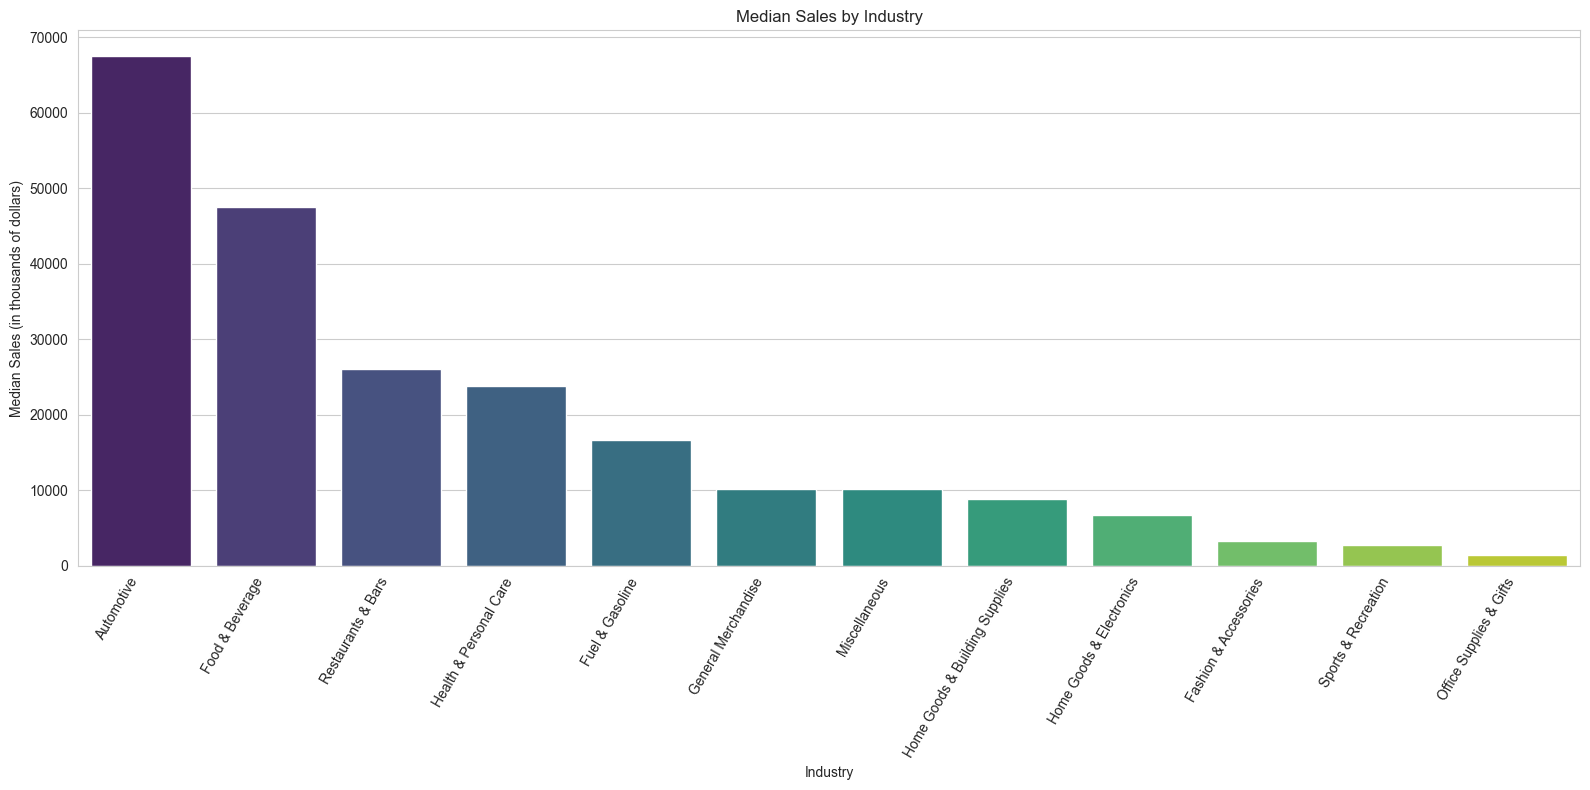

In [13]:
# Visualize the distribution of sales for various industry
plt.figure(figsize=(16, 8))
sns.barplot(x = top_performing_industry.index, y = top_performing_industry.values, palette='viridis')
plt.title('Median Sales by Industry')
plt.xlabel('Industry')
plt.ylabel('Median Sales (in thousands of dollars)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

## **Recommended Strategies**
# 1. Prioritize operational support and capital allocation towards Automotive and Food & Beverage since they generate the vast majority of the revenue cost.

# 2. For the Higher performers industries such as Automotive and Food & Beverage represents the essential consumer spending showing greater overall volume base.

#### **Trends in sales for the Top performing industries**

In [14]:
# Here we create a function that visualizes the trends in sales for the top performing industries
def plot_top_performing_industries_sales_trend(
        df, top_n = 5, year_col = 'year',
        industry_col = 'industry', sales_col = 'sales'
):

  # identify the top performing industries based on their median sales
  top_industries = (
      df.groupby(industry_col)[sales_col].median().nlargest(top_n).index.to_list()
  )

  # filter the dataset for only those top industries
  df_filtered = df[df[industry_col].isin(top_industries)]

  # Aggregate the median sales per year per industries
  trend_data = (
      df_filtered.groupby([year_col, industry_col])[sales_col].sum().reset_index()
  )

  # Plotting the line chart
  plt.figure(figsize=(15, 6))
  sns.lineplot(
      data=trend_data,
      x=year_col,
      y=sales_col,
      hue=industry_col,
      marker="o",
      linewidth=2.5,
  )

  plt.title(
      f"Sales Trend Over Time for Top {top_n} Industries",
      fontsize=14,
      fontweight="bold",
  )
  plt.xlabel("Year", fontsize=12)
  plt.ylabel("Total Sales", fontsize=12)
  plt.grid(True, linestyle="--", alpha=0.6)
  plt.legend(title="Industry", bbox_to_anchor=(1.05, 1), loc="upper left")

  plt.tight_layout()
  plt.show()


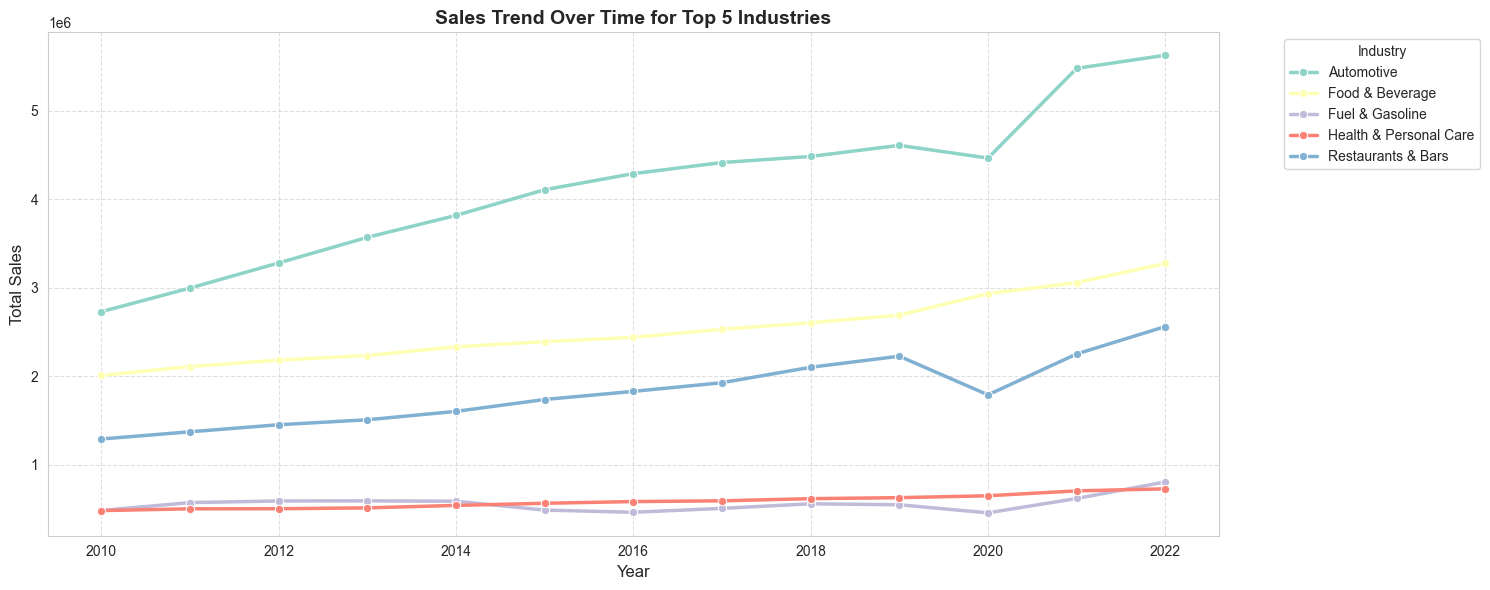

In [15]:
# Here we call out the function
plot_top_performing_industries_sales_trend(df, top_n = 5)

### **Summary Observations (2010 – 2022)**

* The Automotive sector consistently leads all industries by a significant margin. Despite a brief dip in 2020 (~$4.5M), it experienced sharp growth post-2020, reaching over $5.6M in total sales by 2022.

* Resilient Steady Growth (Food & Beverage): The Food & Beverage industry displays consistent, linear upward trajectory across the entire 12-year timeline. Remarkably, it showed virtually no decline during the 2020 pandemic period, rising steadily from ~$2.0M in 2010 to over $3.2M in 2022.

* High Volatility & Pandemic Impact (Restaurants & Bars): Restaurants & Bars maintained steady upward growth through 2019 (~$2.2M). However, it experienced a steep decline in 2020 down to $1.8M due to global lockdown restrictions, followed by a strong recovery through 2022 ($2.5M).

### **Recommended strategies**
1. Given the rapid acceleration in total sales for post 2020 (COVID), allocate capital and marketing resources towards Automotive dealer inventory and parts supply chain optimization

2. Utilize Food & Beverages as the core defensive hedge in economic downl=turn s given its completely linear growth which remains unaffected by the global disruptions.

3. Establish flexible operational structures (adopt hybrid delivery models) for Restaurants & Bars to mitigate sudden external demand shocks like COVID pandemic.

In [16]:
# Here map the months (1 - 12) to Quarters (Q1 - Q4)
mapped_month = {
      1: "Q1", 2: "Q1", 3: "Q1", 4: "Q2", 5: "Q2", 6: "Q2", 7: "Q3", 8: "Q3", 9: "Q3", 10: "Q4", 11: "Q4", 12: "Q4",
}
df['quarterly'] = df['month'].map(mapped_month)

In [17]:
top_performing_industry = df.groupby('industry')['sales'].median().sort_values(ascending = False)
display(top_performing_industry.head(5))

# we grouped by median since its robust to outliers
# create csv file for the top performing industries
top_performing_industry.to_csv('top_performing_industries_median_sales.csv', index = False)


industry
Automotive                67514.0
Food & Beverage           47532.0
Restaurants & Bars        26023.0
Health & Personal Care    23799.0
Fuel & Gasoline           16650.0
Name: sales, dtype: float64

### **Peak Quarterly Sales by Industry 2018**

In [19]:
# Here we create a function that visualizes the top_peak quarters for sales in the year 2018
def visualize_top_industry_peak_quarterly_sales_2018(
        df, year_target=2018, year_col='year', month_col='quarterly',
        top_performing_industries=5,
        industry_col='industry', sales_col='sales',
):
    # Aggregate sales into quarters (Q1 - Q4) then identify the peak quarters for the top industry
    df_2018 = df[df[year_col] == year_target].copy()

    if df_2018.empty:
        raise ValueError(f"There's no data found for the year {year_target}.")

    # Identify top performing industries by total sales in 2020(COVID YEAR)
    top_performing_industry_sales = df_2018.groupby(industry_col)[sales_col].sum().nlargest(
        top_performing_industries).index.to_list()

    df_top = df_2018[df_2018[industry_col].isin(top_performing_industry_sales)]

    # Aggregate the total sales by industry amd quarter
    quarterly_sales = df_top.groupby([industry_col, 'quarterly'])[sales_col].sum().reset_index()

    # Find the peak quarter sales for each industry
    peak_quarters = quarterly_sales.loc[
        quarterly_sales.groupby(industry_col)[sales_col].idxmax()
    ].sort_values(by=sales_col, ascending=False)

    print(f"=== PEAK QUARTERLY SALES BY INDUSTRY ({year_target}) ===")
    for _, row in peak_quarters.iterrows():
        print(
            f'Industry:{row[industry_col]:<30} | Peak Quarter:'
            f" {row['quarterly']} | Sales: ${row[sales_col]:,.2f}"
        )

    # Create pivot table for the Heatmap
    pivot_quarter = quarterly_sales.pivot(index=industry_col, columns='quarterly', values=sales_col)

    # Here ensure the quarters appear in the chronological order (Q1 -> Q4)
    q_order = [q for q in ['Q1', 'Q2', 'Q3', 'Q4'] if q in pivot_quarter.columns]
    pivot_quarter = pivot_quarter[q_order]

    # Plot the Heatmap
    fig, ax = plt.subplots(figsize=(10, 5))

    sns.heatmap(pivot_quarter, cmap="YlGnBu", annot=True, fmt=",.0f",
                cbar_kws={"label": "Quarterly Sales ($)"}, ax=ax,
                linewidths=1, linecolor="white", )

    ax.set_title(f"Quarterly Sales Breakdown & Peak Quarters ({year_target})",
                 fontsize=14,
                 fontweight="bold",
                 pad=15, )

    ax.set_xlabel("Quarter", fontsize=12)
    ax.set_ylabel("Top Performing Industry", fontsize=12)

    plt.tight_layout()
    plt.show()

    # return peak_quarters

=== PEAK QUARTERLY SALES BY INDUSTRY (2018) ===
Industry:Automotive                     | Peak Quarter: Q2 | Sales: $1,157,454.00
Industry:Food & Beverage                | Peak Quarter: Q4 | Sales: $682,787.00
Industry:Restaurants & Bars             | Peak Quarter: Q3 | Sales: $543,176.00
Industry:General Merchandise            | Peak Quarter: Q4 | Sales: $473,299.00
Industry:Home Goods & Electronics       | Peak Quarter: Q4 | Sales: $388,845.00


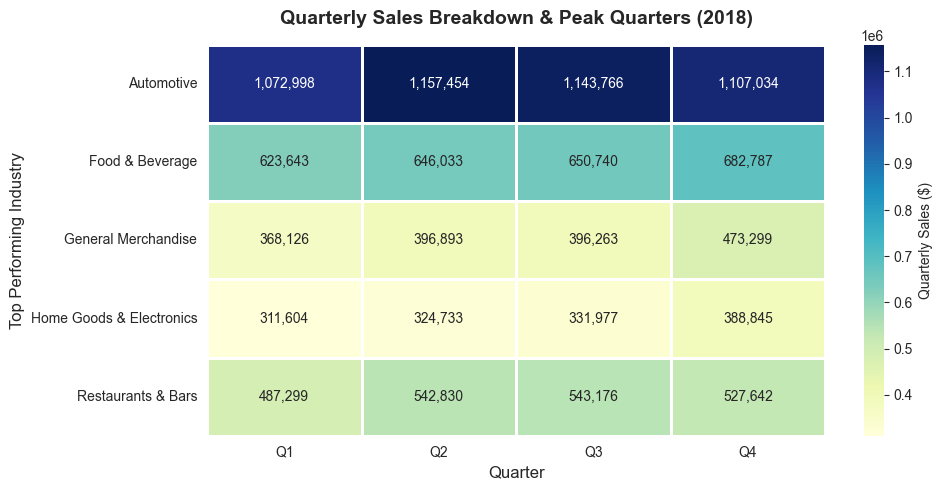

In [21]:
# Here we call out the function to visualize the quarterly sales during 2022
visualize_top_industry_peak_quarterly_sales_2018(df, year_target = 2018)

### **Peak Quarterly sales in 2019**

In [22]:
# Here we create a function that visualizes the top_peak quarters for sales in the year 2020
def visualize_top_industry_peak_quarterly_sales_2019(
        df, year_target = 2019, year_col = 'year', month_col = 'quarterly',
        top_performing_industries = 5,
        industry_col = 'industry', sales_col = 'sales',
):

    # Aggregate sales into quarters (Q1 - Q4) then identify the peak quarters for the top industry
    df_2019 = df[df[year_col] == year_target].copy()

    if df_2019.empty:
        raise ValueError(f"There's no data found for the year {year_target}.")

    # Identify top performing industries by total sales in 2020(COVID YEAR)
    top_performing_industry_sales = df_2019.groupby(industry_col)[sales_col].sum().nlargest(top_performing_industries).index.to_list()

    df_top = df_2019[df_2019[industry_col].isin(top_performing_industry_sales)]

    # Aggregate the total sales by industry amd quarter
    quarterly_sales = df_top.groupby([industry_col, 'quarterly'])[sales_col].sum().reset_index()

    # Find the peak quarter sales for each industry
    peak_quarters = quarterly_sales.loc[
        quarterly_sales.groupby(industry_col)[sales_col].idxmax()
    ].sort_values(by = sales_col, ascending = False)

    print(f"=== PEAK QUARTERLY SALES BY INDUSTRY ({year_target}) ===")
    for _, row in peak_quarters.iterrows():
        print(
            f'Industry:{row[industry_col]:<30} | Peak Quarter:'
            f" {row['quarterly']} | Sales: ${row[sales_col]:,.2f}"
        )

    # Create pivot table for the Heatmap
    pivot_quarter = quarterly_sales.pivot(index = industry_col, columns = 'quarterly', values = sales_col)

    # Here ensure the quarters appear in the chronological order (Q1 -> Q4)
    q_order = [q for q in ['Q1', 'Q2', 'Q3', 'Q4'] if q in pivot_quarter.columns]
    pivot_quarter = pivot_quarter[q_order]

    # Plot the Heatmap
    fig, ax = plt.subplots(figsize = (10, 5))

    sns.heatmap(pivot_quarter, cmap="YlGnBu", annot=True, fmt=",.0f",
                cbar_kws={"label": "Quarterly Sales ($)"}, ax=ax,
                linewidths=1,linecolor="white",)

    ax.set_title(f"Quarterly Sales Breakdown & Peak Quarters ({year_target})",
      fontsize=14,
      fontweight="bold",
      pad=15,)

    ax.set_xlabel("Quarter", fontsize=12)
    ax.set_ylabel("Top Performing Industry", fontsize=12)

    plt.tight_layout()
    plt.show()

    # return peak_quarters

=== PEAK QUARTERLY SALES BY INDUSTRY (2019) ===
Industry:Automotive                     | Peak Quarter: Q3 | Sales: $1,200,598.00
Industry:Food & Beverage                | Peak Quarter: Q4 | Sales: $703,595.00
Industry:Restaurants & Bars             | Peak Quarter: Q3 | Sales: $571,468.00
Industry:General Merchandise            | Peak Quarter: Q4 | Sales: $471,525.00
Industry:Home Goods & Electronics       | Peak Quarter: Q4 | Sales: $413,316.00


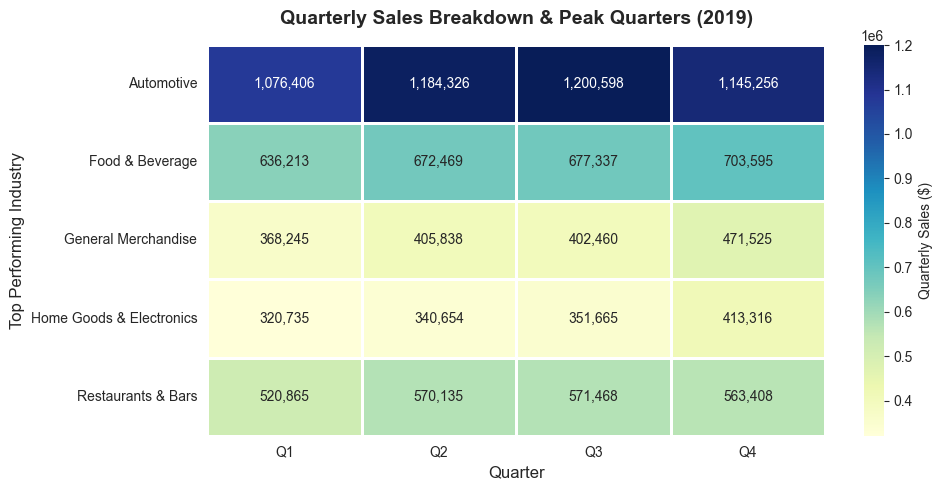

In [23]:
# Here we call out the function to visualize the quarterly sales during 2019
visualize_top_industry_peak_quarterly_sales_2019(df, year_target = 2019)

### **Strategic Observations**
The Automotive generates a massive volume Dominance scale which generates over USD 4.46 million in annual sales, Automotive accounts for more than  36 % of total revenue generated across the top 5 sectors. Sales peaked at Q3 (USD 1.23M) showing strong momentum in the second half of the year.

Food & Beverages maintained tight quarterly sales between USD 708 K - 753 K  resulting in an extremely low volatility spread of 6.23 %. The sector serves as the most dependable baseline revenue source during macroeconomic shocks.

Home Goods & Electronics achieved massive 50.82% expansion from Q1 (USD 338,240) to Q4 (USD 510,127). Driven by home improvements trends, remote work hard-ware and the holiday shopping near the end of Q4, the sector holds the highest quarterly acceleration rate.


### **Recommended Asset Allocation**
1. CORE ANCHOR ALLOCATION (40% Weight): Food & Beverage. Target; Capital preservation and stable dividend yields

   The minimal revenue variance across quarters provides downside protection regardless of macroeconomic conditions (COVID pandemic scenario)

2. GROWTH ENGINE ALLOCATION (35% Weight): Automotive. Here's the target; high revenue throughput with capital appreciation.

   High consumer ticket size and strong Q3 - Q4 purchasing cycles drives the largest share of the top company's growth in revenue.

3. OPPORTUNISTIC ALLOCATION (15% Weight): Home Goods & Electronics whose target is the upside seasonal momentum.

   Here by capitalizing on the second half acceleration (Q3 - Q4 surge), we could easily optimize the inventory capital need of Q4 holiday demands from customers.



### **Peak Quarterly Sales by Industry (2020)**

In [23]:
# Here we create a function that visualizes the top_peak quarters for sales in the year 2022
def visualize_top_industry_peak_quarterly_sales_2020(
        df, year_target=2020, year_col='year', month_col='quarterly',
        top_performing_industries=5,
        industry_col='industry', sales_col='sales',
):
    # Aggregate sales into quarters (Q1 - Q4) then identify the peak quarters for the top industry
    df_2020 = df[df[year_col] == year_target].copy()

    if df_2020.empty:
        raise ValueError(f"There's no data found for the year {year_target}.")

    # Identify top performing industries by total sales in 2020(COVID YEAR)
    top_performing_industry_sales = df_2020.groupby(industry_col)[sales_col].sum().nlargest(
        top_performing_industries).index.to_list()

    df_top = df_2020[df_2020[industry_col].isin(top_performing_industry_sales)]

    # Aggregate the total sales by industry amd quarter
    quarterly_sales = df_top.groupby([industry_col, 'quarterly'])[sales_col].sum().reset_index()

    # Find the peak quarter sales for each industry
    peak_quarters = quarterly_sales.loc[
        quarterly_sales.groupby(industry_col)[sales_col].idxmax()
    ].sort_values(by=sales_col, ascending=False)

    print(f"=== PEAK QUARTERLY SALES BY INDUSTRY ({year_target}) ===")
    for _, row in peak_quarters.iterrows():
        print(
            f'Industry:{row[industry_col]:<30} | Peak Quarter:'
            f" {row['quarterly']} | Sales: ${row[sales_col]:,.2f}"
        )

    # Create pivot table for the Heatmap
    pivot_quarter = quarterly_sales.pivot(index=industry_col, columns='quarterly', values=sales_col)

    # Here ensure the quarters appear in the chronological order (Q1 -> Q4)
    q_order = [q for q in ['Q1', 'Q2', 'Q3', 'Q4'] if q in pivot_quarter.columns]
    pivot_quarter = pivot_quarter[q_order]

    # Plot the Heatmap
    fig, ax = plt.subplots(figsize=(10, 5))

    sns.heatmap(pivot_quarter, cmap="YlGnBu", annot=True, fmt=",.0f",
                cbar_kws={"label": "Quarterly Sales ($)"}, ax=ax,
                linewidths=1, linecolor="white", )

    ax.set_title(f"Quarterly Sales Breakdown & Peak Quarters ({year_target})",
                 fontsize=14,
                 fontweight="bold",
                 pad=15, )

    ax.set_xlabel("Quarter", fontsize=12)
    ax.set_ylabel("Top Performing Industry", fontsize=12)

    plt.tight_layout()
    plt.show()

    # return peak_quarters

=== PEAK QUARTERLY SALES BY INDUSTRY (2020) ===
Industry:Automotive                     | Peak Quarter: Q3 | Sales: $1,232,712.00
Industry:Food & Beverage                | Peak Quarter: Q4 | Sales: $752,567.00
Industry:Home Goods & Electronics       | Peak Quarter: Q4 | Sales: $510,127.00
Industry:Restaurants & Bars             | Peak Quarter: Q1 | Sales: $480,257.00
Industry:General Merchandise            | Peak Quarter: Q4 | Sales: $470,653.00


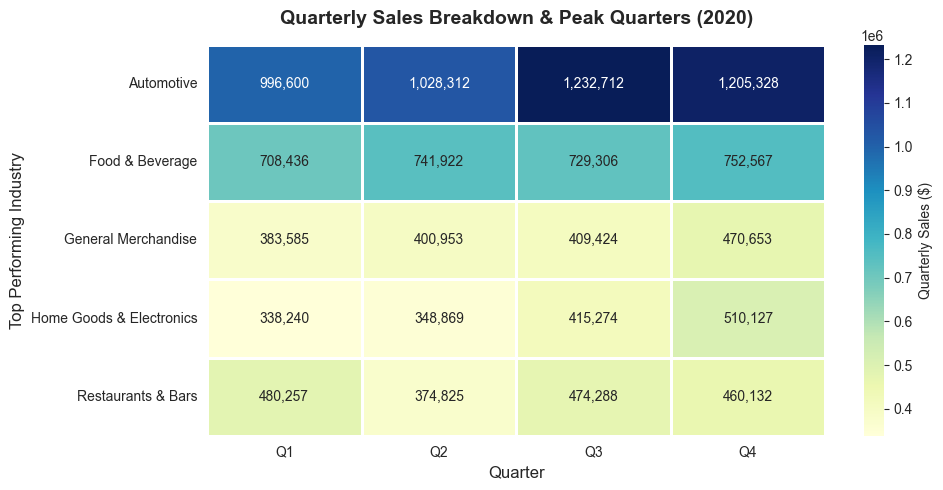

In [26]:
# Here we call out the function to visualize the quarterly sales during 2022
visualize_top_industry_peak_quarterly_sales_2020(df, year_target = 2020)

In [27]:
# Here we create a function that visualizes the top_peak quarters for sales in the year 2022
def visualize_top_industry_peak_quarterly_sales_2021(
        df, year_target=2021, year_col='year', month_col='quarterly',
        top_performing_industries=5,
        industry_col='industry', sales_col='sales',
):
    # Aggregate sales into quarters (Q1 - Q4) then identify the peak quarters for the top industry
    df_2021 = df[df[year_col] == year_target].copy()

    if df_2021.empty:
        raise ValueError(f"There's no data found for the year {year_target}.")

    # Identify top performing industries by total sales in 2020(COVID YEAR)
    top_performing_industry_sales = df_2021.groupby(industry_col)[sales_col].sum().nlargest(
        top_performing_industries).index.to_list()

    df_top = df_2021[df_2021[industry_col].isin(top_performing_industry_sales)]

    # Aggregate the total sales by industry amd quarter
    quarterly_sales = df_top.groupby([industry_col, 'quarterly'])[sales_col].sum().reset_index()

    # Find the peak quarter sales for each industry
    peak_quarters = quarterly_sales.loc[
        quarterly_sales.groupby(industry_col)[sales_col].idxmax()
    ].sort_values(by=sales_col, ascending=False)

    print(f"=== PEAK QUARTERLY SALES BY INDUSTRY ({year_target}) ===")
    for _, row in peak_quarters.iterrows():
        print(
            f'Industry:{row[industry_col]:<30} | Peak Quarter:'
            f" {row['quarterly']} | Sales: ${row[sales_col]:,.2f}"
        )

    # Create pivot table for the Heatmap
    pivot_quarter = quarterly_sales.pivot(index=industry_col, columns='quarterly', values=sales_col)

    # Here ensure the quarters appear in the chronological order (Q1 -> Q4)
    q_order = [q for q in ['Q1', 'Q2', 'Q3', 'Q4'] if q in pivot_quarter.columns]
    pivot_quarter = pivot_quarter[q_order]

    # Plot the Heatmap
    fig, ax = plt.subplots(figsize=(10, 5))

    sns.heatmap(pivot_quarter, cmap="YlGnBu", annot=True, fmt=",.0f",
                cbar_kws={"label": "Quarterly Sales ($)"}, ax=ax,
                linewidths=1, linecolor="white", )

    ax.set_title(f"Quarterly Sales Breakdown & Peak Quarters ({year_target})",
                 fontsize=14,
                 fontweight="bold",
                 pad=15, )

    ax.set_xlabel("Quarter", fontsize=12)
    ax.set_ylabel("Top Performing Industry", fontsize=12)

    plt.tight_layout()
    plt.show()

    # return peak_quarters

=== PEAK QUARTERLY SALES BY INDUSTRY (2021) ===
Industry:Automotive                     | Peak Quarter: Q2 | Sales: $1,508,526.00
Industry:Food & Beverage                | Peak Quarter: Q4 | Sales: $818,510.00
Industry:Restaurants & Bars             | Peak Quarter: Q3 | Sales: $600,710.00
Industry:Home Goods & Electronics       | Peak Quarter: Q4 | Sales: $562,062.00
Industry:General Merchandise            | Peak Quarter: Q4 | Sales: $525,565.00


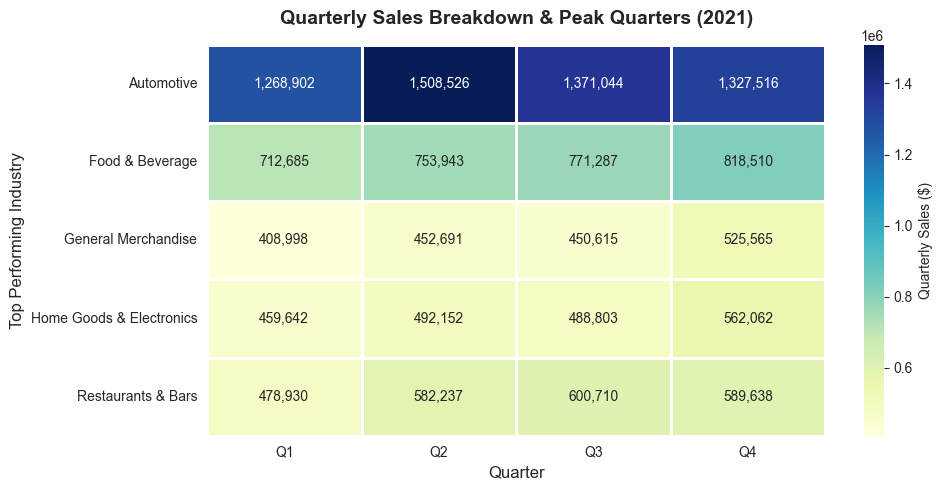

In [28]:
# Here we call out the function to visualize the quarterly sales during 2022
visualize_top_industry_peak_quarterly_sales_2021(df, year_target = 2021)

In [31]:
# Here we create a function that visualizes the top_peak quarters for sales in the year 2022
def visualize_top_industry_peak_quarterly_sales_2022(
        df, year_target=2022, year_col='year', month_col='quarterly',
        top_performing_industries=5,
        industry_col='industry', sales_col='sales',
):
    # Aggregate sales into quarters (Q1 - Q4) then identify the peak quarters for the top industry
    df_2022 = df[df[year_col] == year_target].copy()

    if df_2022.empty:
        raise ValueError(f"There's no data found for the year {year_target}.")

    # Identify top performing industries by total sales in 2020(COVID YEAR)
    top_performing_industry_sales = df_2022.groupby(industry_col)[sales_col].sum().nlargest(
        top_performing_industries).index.to_list()

    df_top = df_2022[df_2022[industry_col].isin(top_performing_industry_sales)]

    # Aggregate the total sales by industry amd quarter
    quarterly_sales = df_top.groupby([industry_col, 'quarterly'])[sales_col].sum().reset_index()

    # Find the peak quarter sales for each industry
    peak_quarters = quarterly_sales.loc[
        quarterly_sales.groupby(industry_col)[sales_col].idxmax()
    ].sort_values(by=sales_col, ascending=False)

    print(f"=== PEAK QUARTERLY SALES BY INDUSTRY ({year_target}) ===")
    for _, row in peak_quarters.iterrows():
        print(
            f'Industry:{row[industry_col]:<30} | Peak Quarter:'
            f" {row['quarterly']} | Sales: ${row[sales_col]:,.2f}"
        )

    # Create pivot table for the Heatmap
    pivot_quarter = quarterly_sales.pivot(index=industry_col, columns='quarterly', values=sales_col)

    # Here ensure the quarters appear in the chronological order (Q1 -> Q4)
    q_order = [q for q in ['Q1', 'Q2', 'Q3', 'Q4'] if q in pivot_quarter.columns]
    pivot_quarter = pivot_quarter[q_order]

    # Plot the Heatmap
    fig, ax = plt.subplots(figsize=(10, 5))

    sns.heatmap(pivot_quarter, cmap="YlGnBu", annot=True, fmt=",.0f",
                cbar_kws={"label": "Quarterly Sales ($)"}, ax=ax,
                linewidths=1, linecolor="white", )

    ax.set_title(f"Quarterly Sales Breakdown & Peak Quarters ({year_target})",
                 fontsize=14,
                 fontweight="bold",
                 pad=15, )

    ax.set_xlabel("Quarter", fontsize=12)
    ax.set_ylabel("Top Performing Industry", fontsize=12)

    plt.tight_layout()
    plt.show()

    # return peak_quarters

=== PEAK QUARTERLY SALES BY INDUSTRY (2022) ===
Industry:Automotive                     | Peak Quarter: Q2 | Sales: $1,471,718.00
Industry:Food & Beverage                | Peak Quarter: Q4 | Sales: $876,532.00
Industry:Restaurants & Bars             | Peak Quarter: Q3 | Sales: $665,115.00
Industry:Home Goods & Electronics       | Peak Quarter: Q4 | Sales: $578,396.00
Industry:General Merchandise            | Peak Quarter: Q4 | Sales: $541,353.00


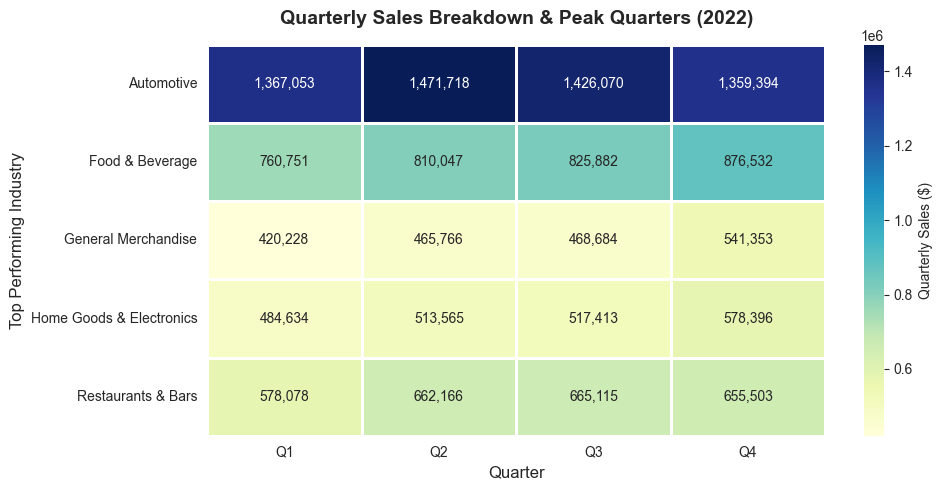

In [32]:
# Here we call out the function to visualize the quarterly sales during 2022
visualize_top_industry_peak_quarterly_sales_2022(df, year_target = 2022)

#### **Analyzing the Top business based on the revenue generated**

In [25]:
# Here we create a function that analyzes and visualizes the top business based on the revenue generated
def analyze_visualize_top_performing_businesses(
        df, category_col = 'kind_of_business',
        sales_col = 'sales', top_n = 10, palette = 'Blues_r', figsize = (15, 6)
):

    # Group then compute the category for top N businesses
    top_performing_business = (df.groupby(category_col)[sales_col].sum().nlargest(10).reset_index())

    # Compute for the total metrics (sales)
    overall_sales = df[sales_col].sum()

    # Calculate the percentage shares of the total market (total revenue generated)
    top_performing_business['sales_percentage_shares'] = (top_performing_business[sales_col] / overall_sales * 100).round(2)
    top_performing_business['formatted_sales'] = top_performing_business[sales_col].apply(lambda x: f"${x:,.2f}")

    # Print the summary table
    print(f"=== TOP {top_n} KINDS OF BUSINESS BY REVENUE GENERATED ===")
    for rank, (_, row) in enumerate(top_performing_business.iterrows(), 1):
        print(
            f"{rank:2d}. {row[category_col]:<45} | Sales:"
            f"{row['formatted_sales']:>15} | Share: {row['sales_percentage_shares']:5.2f}%"
        )

    # Plotting the visualization
    fig, ax = plt.subplots(figsize = figsize)

    sns.barplot(
        data = top_performing_business, x = sales_col, y = category_col,
        palette = palette, ax = ax, hue = category_col, legend = False,
    )

    # Annotate bar labels with percentage share
    max_sales = top_performing_business[sales_col].max()
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            pct = (width / overall_sales) * 100
            ax.annotate(
                f" ${width:,.0f} ({pct:.1f}%",
                (width, p.get_y() + p.get_height() / 2.0),
                ha = 'left', va = 'center',
                xytext = (5, 0),
                textcoords = 'offset points', fontweight = 'bold',
            )

    # Formatting plot titles and axes
    ax.set_title(
      f"Top {top_n} Best Performing Kinds of Business",
      fontsize=14,
      fontweight="bold",
      pad=15,
   )

    ax.set_xlabel("Total Sales ($)", fontsize=12, labelpad=10)
    ax.set_ylabel("Kind of Business", fontsize=12, labelpad=10)
    ax.set_xlim(0, max_sales * 1.25)  # Add padding for labels
    ax.xaxis.set_major_formatter("${x:,.0f}")

    sns.despine(top=True, right=True)
    plt.tight_layout()
    plt.show()

    return top_performing_business


=== TOP 10 KINDS OF BUSINESS BY REVENUE GENERATED ===
 1. Motor vehicle and parts dealers               | Sales: $14,531,121.00 | Share:  7.48%
 2. Automobile and other motor vehicle dealers    | Sales: $13,310,756.00 | Share:  6.85%
 3. Automobile dealers                            | Sales: $12,389,347.00 | Share:  6.38%
 4. New car dealers                               | Sales: $10,980,583.00 | Share:  5.65%
 5. Food and beverage stores                      | Sales:  $9,451,004.00 | Share:  4.87%
 6. General merchandise stores                    | Sales:  $9,038,491.00 | Share:  4.65%
 7. Food services and drinking places             | Sales:  $8,635,492.00 | Share:  4.45%
 8. Nonstore retailers                            | Sales:  $8,511,856.00 | Share:  4.38%
 9. Grocery stores                                | Sales:  $8,463,197.00 | Share:  4.36%
10. Supermarkets and other grocery (except convenience) stores | Sales:  $8,092,220.00 | Share:  4.17%


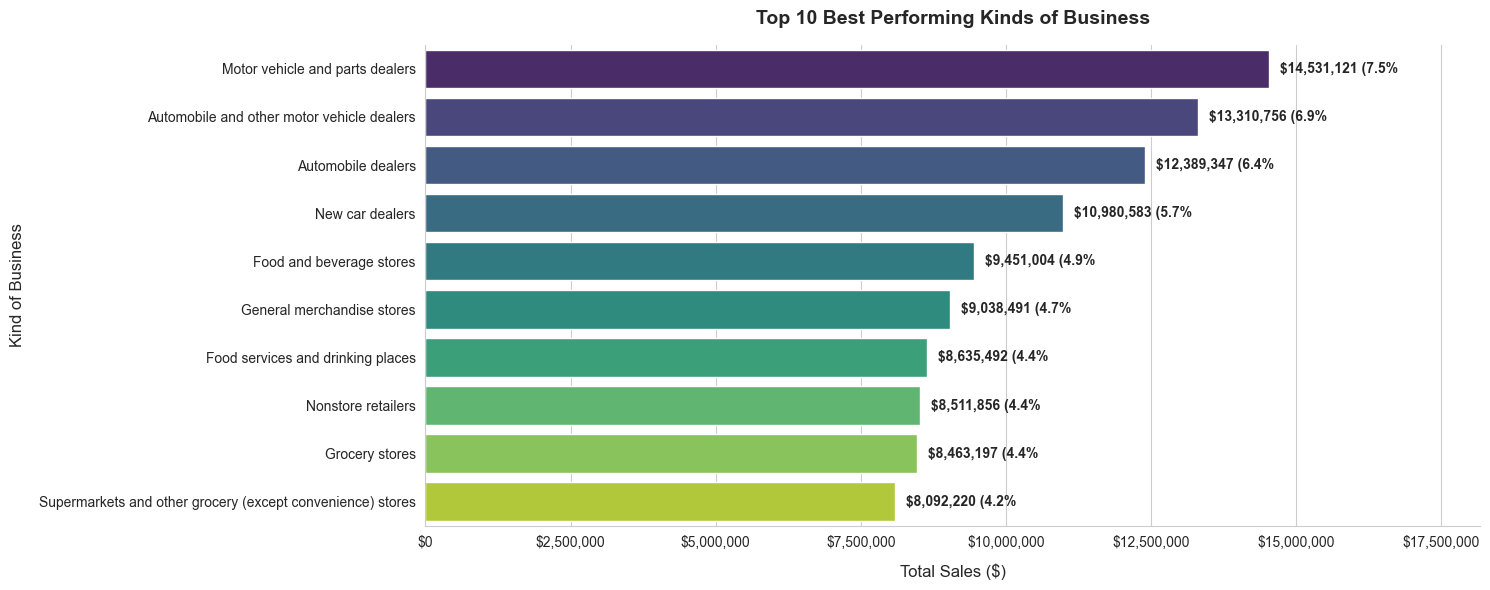

In [26]:
# Here we call the function created
analyze_visualize_top_performing_businesses(df, top_n = 10, palette = 'viridis');

### **Strategic Observations**
The Top 4 categories belong entirely to the Automotive industry which generate USD 51.2 M representing 26.5% of total sales across all business kinds.

Motor Vehicles and parts dealers is the single highest performing business type generating USD 14.5 M which is 7.5 % of the share revenue.

Essential Consumer Retail Stability: Food and grocery sub-sectors represent a major secondary cluster.
"Food and beverage stores" (USD 9.45M / 4.9%), "Grocery stores" (USD 8.46M / 4.4%), and
"Supermarkets" (USD 8.09M / 4.2%) reflect high-volume, resilient consumer demand.